In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
df = pd.read_csv("../dataset/adult.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (48842, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [8]:
print("Dataset Information")

df.info()

Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB


In [9]:
print("Missing Values in Each Column:")

print(df.isnull().sum())

Missing Values in Each Column:
age                 0
workclass         963
fnlwgt              0
education           0
education-num       0
marital-status      0
occupation        966
relationship        0
race                0
sex                 0
capital-gain        0
capital-loss        0
hours-per-week      0
native-country    274
income              0
dtype: int64


In [10]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,48842.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,48842.000000
mean,38.643585,1.896641e+05,10.078089,1079.067626,87.502314,40.422382
std,13.710510,1.056040e+05,2.570973,7452.019058,403.004552,12.391444
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000


In [11]:
# Gender distribution

gender_counts = df["sex"].value_counts()

print("Gender Distribution:")
print(gender_counts)

Gender Distribution:
sex
Male      32650
Female    16192
Name: count, dtype: int64


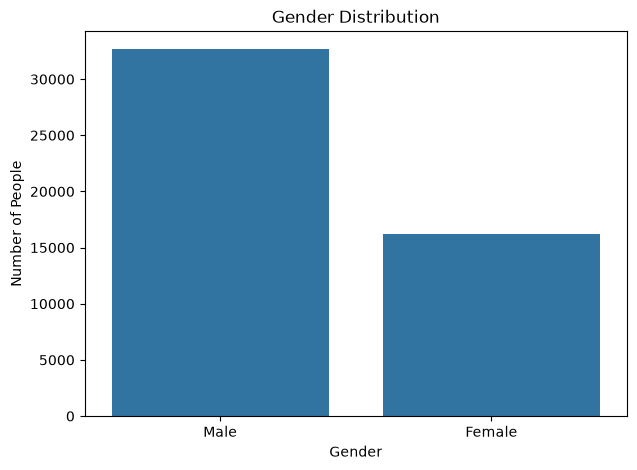

In [12]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of People")

plt.show()

In [13]:
income_counts = df["income"].value_counts()

print("Income Distribution:")
print(income_counts)

Income Distribution:
income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64


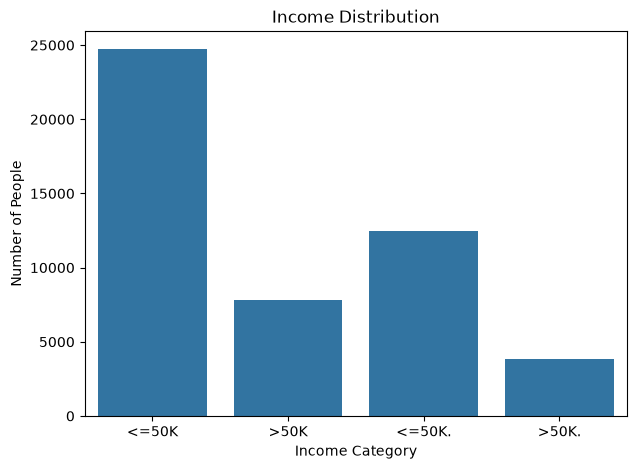

In [14]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="income")

plt.title("Income Distribution")
plt.xlabel("Income Category")
plt.ylabel("Number of People")

plt.show()

In [15]:
gender_income = pd.crosstab(
    df["sex"],
    df["income"]
)

print("Gender vs Income:")
print(gender_income)

Gender vs Income:
income  <=50K  <=50K.  >50K  >50K.
sex                               
Female   9592    4831  1179    590
Male    15128    7604  6662   3256


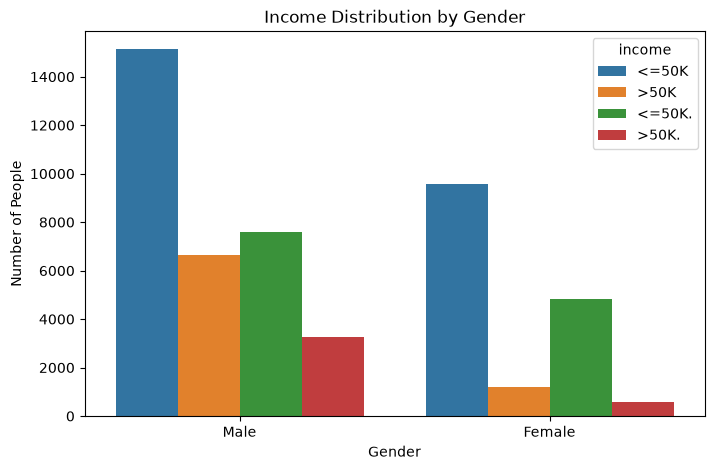

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="sex",
    hue="income"
)

plt.title("Income Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of People")

plt.show()

In [17]:
# Calculate income percentage by gender

gender_income_percentage = pd.crosstab(
    df["sex"],
    df["income"],
    normalize="index"
) * 100

print("Income Percentage by Gender:")
print(gender_income_percentage.round(2))

Income Percentage by Gender:
income  <=50K  <=50K.   >50K  >50K.
sex                                
Female  59.24   29.84   7.28   3.64
Male    46.33   23.29  20.40   9.97


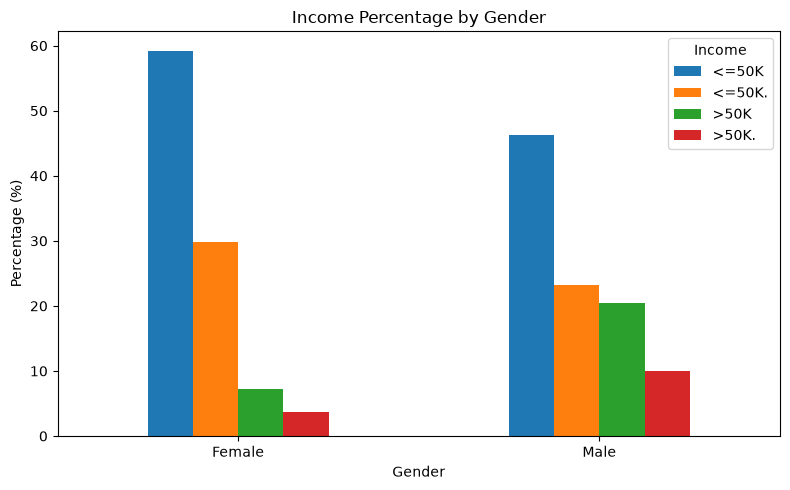

BIAS ANALYSIS OBSERVATION
Female: 7.28% earn more than 50K
Male: 20.40% earn more than 50K
